In [2]:
%load_ext autoreload
%autoreload 2
import os
os.chdir('/nfs/home/dannis/AC-model/TIM')
import numpy as np
import matplotlib.pyplot as plt
from optimization import *
from tqdm import tqdm
import pandas as pd
import seaborn as sns
from time import time
import pickle
import json

In [3]:
def IS_tim_for_loop(action, posterior_samples, n_steps, total_qty, tau, sigma, spread):
    
    n_scenarios = len(posterior_samples['gamma'])
    
    IS_exprs = []
    np.random.seed(42)
    
    noise = np.random.normal(0, 1, (n_scenarios, n_steps + 1))
    
    for p in range(n_scenarios):
        kappa = posterior_samples["kappa"][p]
        gamma = posterior_samples["gamma"][p]
        rho = 2.231  # Or posterior_samples["rho"][p]
        permanent_impact = 0.5 * gamma * total_qty**2 - 0.5 * gamma * np.sum(action[k] * action[k] for k in range(n_steps + 1))
        spread_cost = spread * total_qty
        temporary_impact = (1/2 * (gamma + kappa)) * np.sum(action[k] * action[k] for k in range(n_steps + 1)) # should be estimated
        stochastic_term = 0.0
        for k in range(n_steps + 1):
            inventory_expr_k = total_qty - np.sum(action[i] for i in range(k + 1))
            stochastic_term += inventory_expr_k * noise[p, k]
        stochastic_term = sigma * np.sqrt(tau) * stochastic_term
        transient_impact = kappa * np.sum(
            [[action[k] * (np.sum(action[i] * np.exp(-rho * tau * (k - i)) for i in range(k)))]
            for k in range(n_steps + 1)]
        )
        IS_p = permanent_impact + spread_cost + temporary_impact - stochastic_term + transient_impact
        # print(f'permanent_impact: {permanent_impact:.3g}, temporary_impact: {temporary_impact:.3g}, stochastic_term: {stochastic_term:.3g}, transient_impact: {transient_impact:.3g}')
        IS_exprs.append(IS_p)
    return IS_exprs

def IS_tim(action, posterior_samples, n_steps, total_qty, tau, sigma, spread):
    """
    Pure NumPy implementation of IS_tim_particles.
    Returns realized IS values across posterior scenarios.
    """
    
    n_scenarios = len(posterior_samples['gamma'])
    np.random.seed(42)
    # Gaussian noise: shape (n_scenarios, n_steps+1)
    noise = np.random.normal(0, 1, (n_scenarios, n_steps + 1))
    
    # Extract posterior params
    kappa = np.array(posterior_samples["kappa"])  # (n_scenarios,)
    gamma = np.array(posterior_samples["gamma"])  # (n_scenarios,)
    rho = 2.231  # could also be np.array if sampled
    
    # Precompute action terms
    action = np.asarray(action)
    action_sq_sum = np.sum(action**2)
    action_cumsum = np.cumsum(action)
    inventory = total_qty - action_cumsum  # shape (n_steps+1,)
    
    # Permanent impact
    permanent_impact = 0.5 * gamma * total_qty**2 - 0.5 * gamma * action_sq_sum
    
    # Spread cost (same for all scenarios)
    spread_cost = spread * total_qty
    
    # Temporary impact
    temporary_impact = 0.5 * (gamma + kappa) * action_sq_sum
    
    # Stochastic term: sum_k inventory[k] * noise[p, k]
    stochastic_term = sigma * np.sqrt(tau) * (noise @ inventory)
    
    # Transient impact
    time_idx = np.arange(n_steps + 1)
    # exp(-rho * tau * (k - i)) for k>i
    kernel = np.exp(-rho * tau * (time_idx[None, :] - time_idx[:, None]))
    kernel = np.triu(kernel, k=1)  # zero out k <= i
    
    transient_impact_per_action = action @ (kernel @ action)  # scalar
    transient_impact = kappa * transient_impact_per_action
    
    # IS values per scenario
    IS_exprs = permanent_impact + spread_cost + temporary_impact - stochastic_term + transient_impact
    # print(f'permanent_impact: {permanent_impact}, temporary_impact: {temporary_impact}, stochastic_term: {stochastic_term}, transient_impact: {transient_impact}')
    return IS_exprs


In [14]:
opt_results_dir = '/nfs/home/dannis/AC-model/TIM_opt_results/20250929_vary_mean_5e-5/nTrades150_nScenarios1000_lossThresh450000_chanceThresh5_M1000000_mcmcLabelcombined_scale100_sigma0.95_'
with open(os.path.join(opt_results_dir, 'nScenarios1000_100.pkl'), 'rb') as f:
    opt_result = pd.read_pickle(f)

with open(os.path.join(opt_results_dir, 'config.json')) as f:
    opt_config = json.load(f)
    

In [6]:
opt_config

{'opt_timestamp': '20250929_113829',
 'mcmc_timestamp': '20250916_online_5e-5',
 'n_trades': 150,
 'n_scenarios': 1000,
 'add_samples': False,
 'max_n_scenarios': 400,
 'gap': 100,
 'n_steps': 10,
 'total_qty': 100000.0,
 'tau': 0.1,
 'spread': 0,
 'q': 10000.0,
 'sigma': 0.95,
 'gamma': 5e-05,
 'kappa': 5e-05,
 'rho': 2.231,
 'chance_thresh': 0.05,
 'loss_thresh': 450000.0,
 'M': 1000000.0,
 'mcmc_label': 'combined',
 'scale': 100.0,
 'recenter': True,
 'sample_rho': False}

In [17]:
# posterior_samples = {
#     "kappa": np.random.normal(1e-4, 1e-7, 10),
#     "gamma": np.random.normal(1e-4, 1e-7, 10),
#     "rho": np.random.normal(2.231, 0.1, 10)}

n_steps=10
spread = 0.
tau = 0.1
sigma = 0.45
total_qty = 100000
action = opt_result['trades']
assert (len(action) == n_steps + 1) and np.isclose(np.sum(action), total_qty / scale)

AssertionError: 

/tmp/ipykernel_1035392/1478841628.py:14: DeprecationWarning: Calling np.sum(generator) is deprecated, and in the future will give a different result. Use np.sum(np.fromiter(generator)) or the python sum builtin instead.
  permanent_impact = 0.5 * gamma * total_qty**2 - 0.5 * gamma * np.sum(action[k] * action[k] for k in range(n_steps + 1))
/tmp/ipykernel_1035392/1478841628.py:16: DeprecationWarning: Calling np.sum(generator) is deprecated, and in the future will give a different result. Use np.sum(np.fromiter(generator)) or the python sum builtin instead.
  temporary_impact = (1/2 * (gamma + kappa)) * np.sum(action[k] * action[k] for k in range(n_steps + 1)) # should be estimated
/tmp/ipykernel_1035392/1478841628.py:19: DeprecationWarning: Calling np.sum(generator) is deprecated, and in the future will give a different result. Use np.sum(np.fromiter(generator)) or the python sum builtin instead.
  inventory_expr_k = total_qty - np.sum(action[i] for i in range(k + 1))
/tmp/ipykernel_103

Text(0, 0.5, 'Density')

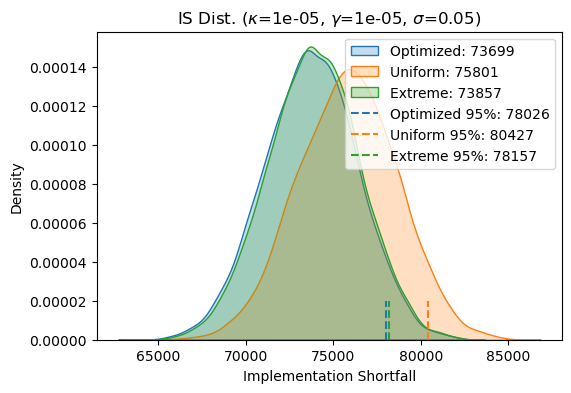

In [88]:
fig, ax = plt.subplots(1, 1, figsize=(6, 4))
i = 0
kappa = 1e-5
gamma = 1e-5
sigma = 0.05
rho = 2.231
n_scenarios = 10000

nTrades = 150
mcmc_label = 'combined'
mcmc_timestamp = '20250918_online15e-5'
scale = 1
gap = 100

posterior_samples = {"gamma": [gamma]*n_scenarios, "kappa": [kappa]*n_scenarios, "rho": [rho]*n_scenarios}
action0 = np.array(opt_result['trades']) * 100
IS_arr0 = IS_tim(action0, posterior_samples, n_steps=10, total_qty=100000, tau=0.1, sigma=sigma, spread=0.)
action1 = np.ones_like(opt_result['trades']) * total_qty / (len(opt_result['trades']))  # uniform trades
assert np.isclose(np.sum(action1), total_qty)
IS_arr1 = IS_tim_for_loop(action1, posterior_samples, n_steps=10, total_qty=100000, tau=0.1, sigma=sigma, spread=0.)
action2 = increase_front_and_back_load(action0, increase_fraction=0.2)
assert np.isclose(np.sum(action2), total_qty)
IS_arr2 = IS_tim_for_loop(action2, posterior_samples, n_steps=10, total_qty=100000, tau=0.1, sigma=sigma, spread=0.)
sns.kdeplot(IS_arr0, ax=ax, label=f'Optimized: {np.mean(IS_arr0):.0f}', fill=True)
sns.kdeplot(IS_arr1, ax=ax, label=f'Uniform: {np.mean(IS_arr1):.0f}', fill=True)
sns.kdeplot(IS_arr2, ax=ax, label=f'Extreme: {np.mean(IS_arr2):.0f}', fill=True)
ax.vlines(np.percentile(IS_arr0, 95), color='C0', linestyle='--', label=f'Optimized 95%: {np.percentile(IS_arr0, 95):.0f}', ymin=0, ymax=2e-5)
ax.vlines(np.percentile(IS_arr1, 95), color='C1', linestyle='--', label=f'Uniform 95%: {np.percentile(IS_arr1, 95):.0f}', ymin=0, ymax=2e-5)
ax.vlines(np.percentile(IS_arr2, 95), color='C2', linestyle='--', label=f'Extreme 95%: {np.percentile(IS_arr2, 95):.0f}', ymin=0, ymax=2e-5)
ax.legend()
ax.set_title(f'IS Dist. ($\kappa$={kappa}, $\gamma$={gamma}, $\sigma$={sigma})')
ax.set_xlabel('Implementation Shortfall')
ax.set_ylabel('Density')


Processing trace file: /nfs/home/dannis/AC-model/TIM/TIM_MCMC_Results/20250918_online_1e-5/nTrades150_posteriors.pkl
Mean of Kappa: 5.7e-06, STD: 2e-06
Mean of Gamma: 1.44e-05, STD: 2.01e-06
Mean of rho: 5.68, STD: 1.56


/tmp/ipykernel_1035392/1478841628.py:14: DeprecationWarning: Calling np.sum(generator) is deprecated, and in the future will give a different result. Use np.sum(np.fromiter(generator)) or the python sum builtin instead.
  permanent_impact = 0.5 * gamma * total_qty**2 - 0.5 * gamma * np.sum(action[k] * action[k] for k in range(n_steps + 1))
/tmp/ipykernel_1035392/1478841628.py:16: DeprecationWarning: Calling np.sum(generator) is deprecated, and in the future will give a different result. Use np.sum(np.fromiter(generator)) or the python sum builtin instead.
  temporary_impact = (1/2 * (gamma + kappa)) * np.sum(action[k] * action[k] for k in range(n_steps + 1)) # should be estimated
/tmp/ipykernel_1035392/1478841628.py:19: DeprecationWarning: Calling np.sum(generator) is deprecated, and in the future will give a different result. Use np.sum(np.fromiter(generator)) or the python sum builtin instead.
  inventory_expr_k = total_qty - np.sum(action[i] for i in range(k + 1))
/tmp/ipykernel_103

Text(0, 0.5, 'Density')

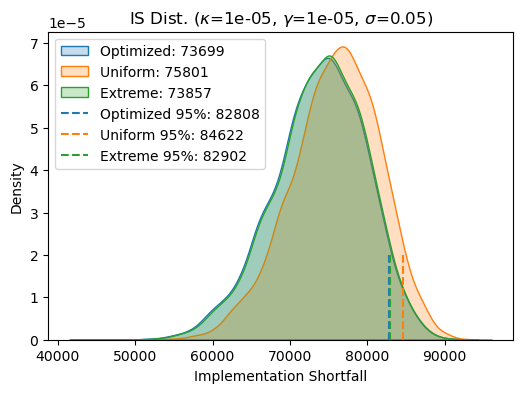

In [87]:
fig, ax = plt.subplots(1, 1, figsize=(6, 4))
i = 0
kappa = 1e-5
gamma = 1e-5
sigma = 0.05
rho = 2.231
n_scenarios = 10000

nTrades = 150
mcmc_label = 'combined'
mcmc_timestamp = '20250918_online_1e-5'
scale = 1
gap = 100
posterior_samples = sample_posteriors(nTrades, 
                                      mcmc_label, mcmc_timestamp, 
                                      n_scenarios, scale, True, gamma, kappa, rho,
                                      gap)
action0 = np.array(opt_result['trades']) * 100
IS_arr0 = IS_tim(action0, posterior_samples, n_steps=10, total_qty=100000, tau=0.1, sigma=sigma, spread=0.)
action1 = np.ones_like(opt_result['trades']) * total_qty / (len(opt_result['trades']))  # uniform trades
assert np.isclose(np.sum(action1), total_qty)
IS_arr1 = IS_tim_for_loop(action1, posterior_samples, n_steps=10, total_qty=100000, tau=0.1, sigma=sigma, spread=0.)
action2 = increase_front_and_back_load(action0, increase_fraction=0.2)
assert np.isclose(np.sum(action2), total_qty)
IS_arr2 = IS_tim_for_loop(action2, posterior_samples, n_steps=10, total_qty=100000, tau=0.1, sigma=sigma, spread=0.)
sns.kdeplot(IS_arr0, ax=ax, label=f'Optimized: {np.mean(IS_arr0):.0f}', fill=True)
sns.kdeplot(IS_arr1, ax=ax, label=f'Uniform: {np.mean(IS_arr1):.0f}', fill=True)
sns.kdeplot(IS_arr2, ax=ax, label=f'Extreme: {np.mean(IS_arr2):.0f}', fill=True)
ax.vlines(np.percentile(IS_arr0, 95), color='C0', linestyle='--', label=f'Optimized 95%: {np.percentile(IS_arr0, 95):.0f}', ymin=0, ymax=2e-5)
ax.vlines(np.percentile(IS_arr1, 95), color='C1', linestyle='--', label=f'Uniform 95%: {np.percentile(IS_arr1, 95):.0f}', ymin=0, ymax=2e-5)
ax.vlines(np.percentile(IS_arr2, 95), color='C2', linestyle='--', label=f'Extreme 95%: {np.percentile(IS_arr2, 95):.0f}', ymin=0, ymax=2e-5)
ax.legend()
ax.set_title(f'IS Dist. ($\kappa$={kappa}, $\gamma$={gamma}, $\sigma$={sigma})')
ax.set_xlabel('Implementation Shortfall')
ax.set_ylabel('Density')

Text(0, 0.5, 'Density')

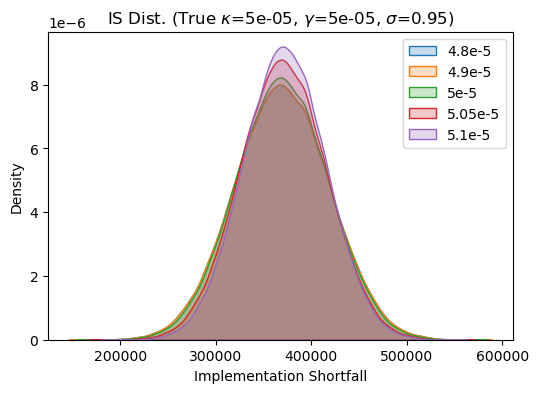

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(6, 4))
i = 0
kappa = 5e-5
gamma = 5e-5
sigma = 0.95
rho = 2.231
n_scenarios = 100000
total_qty = 1e5

nTrades = 30
mcmc_label = 'combined'
mcmc_timestamp = '20250916_online_5e-5'
scale = 1
gap = 100
posterior_samples = {"gamma": [gamma]*n_scenarios, "kappa": [kappa]*n_scenarios, "rho": [rho]*n_scenarios}
IS_data = {}
for mean in ['4.8e-5', '4.9e-5', '5e-5', '5.05e-5', '5.1e-5']:
    opt_results_dir = f'/nfs/home/dannis/AC-model/TIM_opt_results/20250929_vary_mean_{mean}/nTrades150_nScenarios1000_lossThresh450000_chanceThresh5_M1000000_mcmcLabelcombined_scale100_sigma0.95_'
    with open(os.path.join(opt_results_dir, 'nScenarios1000_100.pkl'), 'rb') as f:
        opt_result0 = pd.read_pickle(f)
    action0 = np.array(opt_result0['trades']) * 100
    IS_arr0 = IS_tim(action0, posterior_samples, n_steps=10, total_qty=100000, tau=0.1, sigma=sigma, spread=0.)
    IS_data[mean] = IS_arr0
    sns.kdeplot(IS_arr0, ax=ax, label=f'{mean}', fill=True)
# ax.vlines(np.percentile(IS_arr0, 95), color='C0', linestyle='--', label=f'Optimized 95%: {np.percentile(IS_arr0, 95):.0f}', ymin=0, ymax=2e-5)
# # ax.vlines(np.percentile(IS_arr1, 95), color='C1', linestyle='--', label=f'Uniform 95%: {np.percentile(IS_arr1, 95):.0f}', ymin=0, ymax=2e-5)
# ax.vlines(np.percentile(IS_arr2, 95), color='C2', linestyle='--', label=f'Extreme 95%: {np.percentile(IS_arr2, 95):.0f}', ymin=0, ymax=2e-5)
ax.legend()
ax.set_title(f'IS Dist. (True $\kappa$={kappa}, $\gamma$={gamma}, $\sigma$={sigma})')
ax.set_xlabel('Implementation Shortfall')
ax.set_ylabel('Density')

Text(0, 0.5, 'Density')

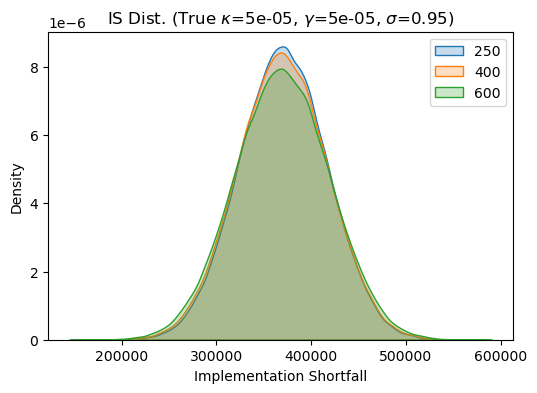

In [6]:
fig, ax = plt.subplots(1, 1, figsize=(6, 4))
i = 0
kappa = 5e-5
gamma = 5e-5
sigma = 0.95
rho = 2.231
n_scenarios = 100000
total_qty = 1e5

nTrades = 30
mcmc_label = 'combined'
mcmc_timestamp = '20251003_5e-5'
scale = 1
gap = 100
posterior_samples = {"gamma": [gamma]*n_scenarios, "kappa": [kappa]*n_scenarios, "rho": [rho]*n_scenarios}
IS_data = {}
for nTrades in [250, 400, 600]:
    opt_results_dir = f'/nfs/home/dannis/AC-model/TIM_opt_results/20251005_vary_chance_thresh_sample_rho_uncentered_5e-5/nTrades{nTrades}_nScenarios1000_lossThresh450000_chanceThresh5_M1000000_mcmcLabelcombined_scale100_sigma0.95_'
    with open(os.path.join(opt_results_dir, 'nScenarios1000_100.pkl'), 'rb') as f:
        opt_result0 = pd.read_pickle(f)
    action0 = np.array(opt_result0['trades']) * 100
    IS_arr0 = IS_tim(action0, posterior_samples, n_steps=10, total_qty=100000, tau=0.1, sigma=sigma, spread=0.)
    IS_data[nTrades] = IS_arr0
    sns.kdeplot(IS_arr0, ax=ax, label=f'{nTrades}', fill=True)
# ax.vlines(np.percentile(IS_arr0, 95), color='C0', linestyle='--', label=f'Optimized 95%: {np.percentile(IS_arr0, 95):.0f}', ymin=0, ymax=2e-5)
# # ax.vlines(np.percentile(IS_arr1, 95), color='C1', linestyle='--', label=f'Uniform 95%: {np.percentile(IS_arr1, 95):.0f}', ymin=0, ymax=2e-5)
# ax.vlines(np.percentile(IS_arr2, 95), color='C2', linestyle='--', label=f'Extreme 95%: {np.percentile(IS_arr2, 95):.0f}', ymin=0, ymax=2e-5)
ax.legend()
ax.set_title(f'IS Dist. (True $\kappa$={kappa}, $\gamma$={gamma}, $\sigma$={sigma})')
ax.set_xlabel('Implementation Shortfall')
ax.set_ylabel('Density')

Text(0.5, 1.0, 'Mean IS vs. Assumed Mean of Kappa and Gamma')

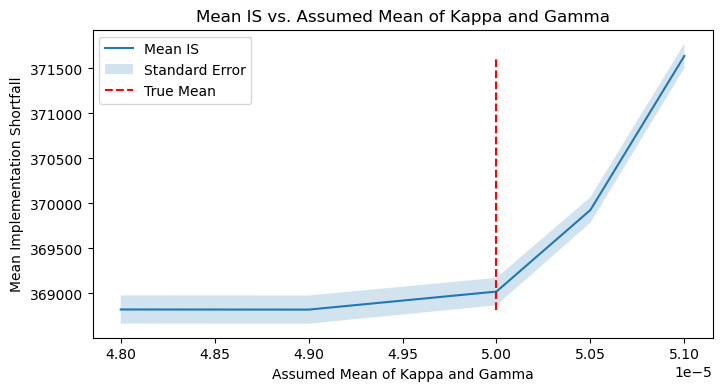

In [36]:
IS_data_df = pd.DataFrame(IS_data)
IS_data_df.columns = IS_data_df.columns.astype(float)
IS_data_df.sort_index(axis=1, inplace=True)
plt.figure(figsize=(8, 4))
x = IS_data_df.mean(axis=0)
plt.plot(x, label='Mean IS')
plt.fill_between(IS_data_df.columns, x - IS_data_df.sem(axis=0), x + IS_data_df.sem(axis=0), alpha=0.2, label='Standard Error')
plt.vlines(5e-5, color='red', linestyle='--', label='True Mean', ymin = x.min(), ymax = x.max())
plt.legend()
plt.xlabel('Assumed Mean of Kappa and Gamma')
plt.ylabel('Mean Implementation Shortfall')
plt.title('Mean IS vs. Assumed Mean of Kappa and Gamma')


Processing trace file: /nfs/home/dannis/AC-model/TIM/TIM_MCMC_Results/20250916_online_5e-5/nTrades30_posteriors.pkl
Mean of Kappa: 2.86e-05, STD: 9.76e-06
Mean of Gamma: 7.14e-05, STD: 9.77e-06
Mean of rho: 5.49, STD: 1.44


/tmp/ipykernel_1035392/1478841628.py:14: DeprecationWarning: Calling np.sum(generator) is deprecated, and in the future will give a different result. Use np.sum(np.fromiter(generator)) or the python sum builtin instead.
  permanent_impact = 0.5 * gamma * total_qty**2 - 0.5 * gamma * np.sum(action[k] * action[k] for k in range(n_steps + 1))
/tmp/ipykernel_1035392/1478841628.py:16: DeprecationWarning: Calling np.sum(generator) is deprecated, and in the future will give a different result. Use np.sum(np.fromiter(generator)) or the python sum builtin instead.
  temporary_impact = (1/2 * (gamma + kappa)) * np.sum(action[k] * action[k] for k in range(n_steps + 1)) # should be estimated
/tmp/ipykernel_1035392/1478841628.py:19: DeprecationWarning: Calling np.sum(generator) is deprecated, and in the future will give a different result. Use np.sum(np.fromiter(generator)) or the python sum builtin instead.
  inventory_expr_k = total_qty - np.sum(action[i] for i in range(k + 1))
/tmp/ipykernel_103

Text(0, 0.5, 'Density')

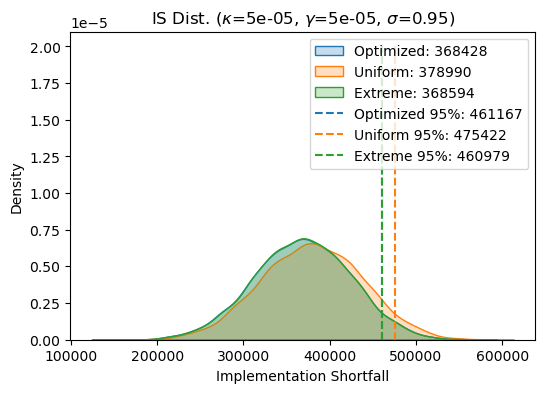

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(6, 4))
i = 0
kappa = 5e-5
gamma = 5e-5
sigma = 0.95
rho = 2.231
n_scenarios = 10000

nTrades = 30
mcmc_label = 'combined'
mcmc_timestamp = '20250916_online_5e-5'
scale = 1
gap = 100
posterior_samples = sample_posteriors(nTrades, 
                                      mcmc_label, mcmc_timestamp, 
                                      n_scenarios, scale, True, gap)
action0 = np.array(opt_result['trades']) * 100
IS_arr0 = IS_tim(action0, posterior_samples, n_steps=10, total_qty=100000, tau=0.1, sigma=sigma, spread=0.)
action1 = np.ones_like(opt_result['trades']) * total_qty / (len(opt_result['trades']))  # uniform trades
assert np.isclose(np.sum(action1), total_qty)
IS_arr1 = IS_tim_for_loop(action1, posterior_samples, n_steps=10, total_qty=100000, tau=0.1, sigma=sigma, spread=0.)
action2 = increase_front_and_back_load(action0, increase_fraction=0.1)
assert np.isclose(np.sum(action2), total_qty)
IS_arr2 = IS_tim_for_loop(action2, posterior_samples, n_steps=10, total_qty=100000, tau=0.1, sigma=sigma, spread=0.)
sns.kdeplot(IS_arr0, ax=ax, label=f'Optimized: {np.mean(IS_arr0):.0f}', fill=True)
sns.kdeplot(IS_arr1, ax=ax, label=f'Uniform: {np.mean(IS_arr1):.0f}', fill=True)
sns.kdeplot(IS_arr2, ax=ax, label=f'Extreme: {np.mean(IS_arr2):.0f}', fill=True)
ax.vlines(np.percentile(IS_arr0, 95), color='C0', linestyle='--', label=f'Optimized 95%: {np.percentile(IS_arr0, 95):.0f}', ymin=0, ymax=2e-5)
ax.vlines(np.percentile(IS_arr1, 95), color='C1', linestyle='--', label=f'Uniform 95%: {np.percentile(IS_arr1, 95):.0f}', ymin=0, ymax=2e-5)
ax.vlines(np.percentile(IS_arr2, 95), color='C2', linestyle='--', label=f'Extreme 95%: {np.percentile(IS_arr2, 95):.0f}', ymin=0, ymax=2e-5)
ax.legend()
ax.set_title(f'IS Dist. ($\kappa$={kappa}, $\gamma$={gamma}, $\sigma$={sigma})')
ax.set_xlabel('Implementation Shortfall')
ax.set_ylabel('Density')

### Violation Probability

In [30]:
opt_results_dir = '/nfs/home/dannis/AC-model/TIM_opt_results/20251005_vary_chance_thresh_sample_rho_uncentered_5e-5/nTrades1000_nScenarios1000_lossThresh450000_chanceThresh5_M1000000_mcmcLabelcombined_scale100_sigma0.95_'

with open(os.path.join(opt_results_dir, 'config.json')) as f:
    opt_config = json.load(f)
    

In [31]:
opt_config

{'opt_timestamp': '20251009_144153',
 'mcmc_timestamp': '20251003_5e-5',
 'n_trades': 1000,
 'n_scenarios': 1000,
 'add_samples': False,
 'max_n_scenarios': 400,
 'gap': 100,
 'n_steps': 10,
 'total_qty': 100000.0,
 'tau': 0.1,
 'spread': 0,
 'q': 10000.0,
 'sigma': 0.95,
 'gamma': 5e-05,
 'kappa': 5e-05,
 'rho': 2.231,
 'chance_thresh': 0.05,
 'loss_thresh': 450000.0,
 'M': 1000000.0,
 'mcmc_label': 'combined',
 'scale': 100.0,
 'recenter': False,
 'sample_rho': True,
 'use_info_file': False}

In [35]:
from optimization import sample_posteriors

gap = opt_config['gap']
n_steps = opt_config['n_steps']
total_qty = opt_config['total_qty']
mcmc_label = opt_config['mcmc_label']
mcmc_timestamp= opt_config['mcmc_timestamp']
tau = opt_config['tau']
spread = opt_config['spread']
sigma = opt_config['sigma']
n_scenarios = opt_config['n_scenarios']
scale = opt_config['scale']
nTrades = opt_config['n_trades']
true_gamma = opt_config['gamma']
true_kappa = opt_config['kappa']
true_rho = opt_config['rho']


In [53]:
posterior_samples = sample_posteriors(nTrades, 
                                      mcmc_label, mcmc_timestamp, 
                                      int(1e6), scale, True, true_gamma, true_kappa, true_rho,
                                      gap)
# posterior_samples = {
#                 "kappa": np.array([true_kappa * scale] * n_scenarios),
#                 "gamma": np.array([true_gamma * scale] * n_scenarios),
#                 "rho": np.array([true_rho] * n_scenarios)
#                     }



Processing trace file: /nfs/home/dannis/AC-model/TIM/TIM_MCMC_Results/20251003_5e-5/nTrades400_posteriors.pkl
Mean of Kappa: 0.00459, STD: 0.000437
Mean of Gamma: 0.0054, STD: 0.000443
Mean of rho: 2.67, STD: 0.329


In [54]:
results = []
opt_results_dir = '/nfs/home/dannis/AC-model/TIM_opt_results/20251005_vary_chance_thresh_sample_rho_uncentered_5e-5/'

for subfolder in os.listdir(opt_results_dir):
    if not os.path.isdir(os.path.join(opt_results_dir, subfolder)):
        continue
    nScenarios = int(subfolder.split('nScenarios')[1].split('_')[0])
    chanceThresh = int(subfolder.split('chanceThresh')[1].split('_')[0])
    nTrades = int(subfolder.split('nTrades')[1].split('_')[0])
    for dir in os.listdir(os.path.join(opt_results_dir, subfolder)):
        if dir.endswith('.pkl'):
            seed = int(dir.split('_')[1].split('.pkl')[0])

            with open(os.path.join(opt_results_dir, subfolder, dir), 'rb') as f:
                opt_result = pd.read_pickle(f)
            action = opt_result['trades']
            if opt_result['status'] != 2:
                print(f'Skipping non-optimal result in {dir}')
                continue


            IS_arr = IS_tim(action, posterior_samples, n_steps, total_qty/scale, tau, sigma, spread)
            violation_prob = np.mean(IS_arr > opt_config['loss_thresh']/scale)
            violation_prob_opt = chanceThresh * (1 - opt_result['chance_slack'])
            results.append({
                'seed': seed,
                'nScenarios': nScenarios,
                'mean_IS': np.mean(IS_arr) * scale,
                'std_IS': np.std(IS_arr) * scale,
                'p_viol': violation_prob,
                'p_viol_opt': violation_prob_opt,
                'chanceThresh': chanceThresh,
                'nTrades': nTrades
            })

Skipping non-optimal result in nScenarios1000_115.pkl
Skipping non-optimal result in nScenarios1000_104.pkl
Skipping non-optimal result in nScenarios1000_108.pkl
Skipping non-optimal result in nScenarios1000_109.pkl
Skipping non-optimal result in nScenarios1000_102.pkl
Skipping non-optimal result in nScenarios1000_107.pkl
Skipping non-optimal result in nScenarios1000_101.pkl
Skipping non-optimal result in nScenarios1000_107.pkl
Skipping non-optimal result in nScenarios1000_127.pkl
Skipping non-optimal result in nScenarios1000_116.pkl
Skipping non-optimal result in nScenarios1000_119.pkl
Skipping non-optimal result in nScenarios1000_111.pkl
Skipping non-optimal result in nScenarios1000_116.pkl
Skipping non-optimal result in nScenarios1000_109.pkl
Skipping non-optimal result in nScenarios1000_121.pkl
Skipping non-optimal result in nScenarios1000_100.pkl
Skipping non-optimal result in nScenarios1000_115.pkl
Skipping non-optimal result in nScenarios1000_114.pkl
Skipping non-optimal result 

In [49]:
df_prob = pd.DataFrame(results)

In [50]:
df_prob

,seed,nScenarios,mean_IS,std_IS,p_viol,p_viol_opt,chanceThresh,nTrades
0,106,1000,371193.678336,44804.690868,0.040,3.9,4,600
1,116,1000,370367.810700,47572.604352,0.051,4.0,4,600
2,124,1000,370904.318527,45805.041937,0.043,4.0,4,600
3,104,1000,370616.589403,47276.440355,0.050,3.8,4,600
4,119,1000,371534.416589,43730.389130,0.039,4.0,4,600
...,...,...,...,...,...,...,...,...
914,110,1000,370943.374593,45620.434062,0.045,5.0,5,400
915,107,1000,371611.066178,43995.864493,0.040,4.7,5,400
916,127,1000,371139.917465,44680.771114,0.041,5.0,5,400
917,101,1000,370730.328088,46950.720507,0.049,5.0,5,400


In [51]:
margin = 0.01
df_prob.groupby(['chanceThresh', 'nTrades']).apply(lambda x: (x['p_viol'] > (x['chanceThresh']/100 + margin)).mean()).unstack()


/tmp/ipykernel_3406803/1466154889.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_prob.groupby(['chanceThresh', 'nTrades']).apply(lambda x: (x['p_viol'] > (x['chanceThresh']/100 + margin)).mean()).unstack()


nTrades,80,150,250,400,600,800,1000,99999
chanceThresh,,,,,,,,
2,NaN,NaN,NaN,0.230769,0.421053,0.400000,0.357143,0.333333
3,NaN,NaN,0.25,0.047619,0.250000,0.357143,0.357143,0.200000
4,NaN,NaN,0.00,0.095238,0.137931,0.259259,0.178571,0.233333
5,NaN,0.0,0.00,0.000000,0.000000,0.000000,0.000000,0.000000
7,NaN,0.0,0.00,0.000000,0.000000,0.000000,0.000000,0.000000
10,0.0,0.0,0.00,0.000000,0.000000,0.000000,0.000000,0.000000


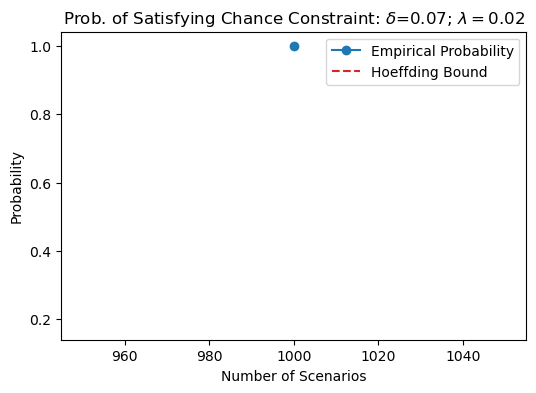

In [14]:
margin = 0.02
delta = opt_config['chance_thresh'] + margin
fig, ax = plt.subplots(1, 1, figsize=(6, 4))
df_prob.groupby('nScenarios').p_viol.apply(lambda x: (x < delta).mean()).plot(ax=ax, label='Empirical Probability', marker='o')
n_scenarios_sorted = np.sort(df_prob.nScenarios.unique())
bound = 1- np.exp(- n_scenarios_sorted * margin ** 2 / 2)
ax.plot(n_scenarios_sorted, bound, linestyle='--', color='C3', label='Hoeffding Bound')
ax.set_xlabel('Number of Scenarios')
ax.set_ylabel('Probability')
ax.set_title(f'Prob. of Satisfying Chance Constraint: $\delta$={delta:.2f}; $\lambda={margin:.2f}$')
ax.legend()

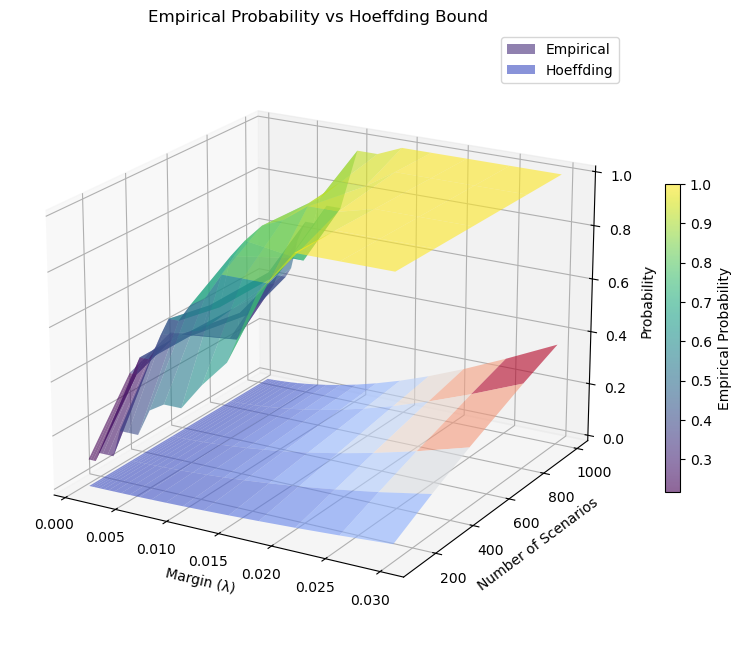

In [58]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Create a range of margin values in logspace
margin_values = np.logspace(np.log10(0.001), np.log10(0.03), 20)  # 20 points from 0.001 to 0.03
n_scenarios_sorted = np.sort(df_prob.nScenarios.unique())

# Create meshgrid for 3D plotting
Margin, NScenarios = np.meshgrid(margin_values, n_scenarios_sorted)

# Calculate empirical probabilities and bounds for each combination
empirical_probs = np.zeros_like(Margin)
hoeffding_bounds = np.zeros_like(Margin)

for i, n_scen in enumerate(n_scenarios_sorted):
    for j, margin in enumerate(margin_values):
        delta = opt_config['chance_thresh'] + margin
        
        # Calculate empirical probability
        subset = df_prob[df_prob['nScenarios'] == n_scen]
        empirical_probs[i, j] = (subset['p_viol'] < delta).mean()
        
        # Calculate Hoeffding bound
        hoeffding_bounds[i, j] = 1 - np.exp(-n_scen * margin**2 / 2)

# Create 3D surface plot

fig = plt.figure(figsize=(10, 8))
ax3 = fig.add_subplot(111, projection='3d')

surf_emp = ax3.plot_surface(Margin, NScenarios, empirical_probs, 
                           cmap='viridis', alpha=0.6, label='Empirical')
surf_bound = ax3.plot_surface(Margin, NScenarios, hoeffding_bounds, 
                             cmap='coolwarm', alpha=0.6, label='Hoeffding')

ax3.set_xlabel('Margin (λ)')
ax3.set_ylabel('Number of Scenarios')
ax3.set_zlabel('Probability')
ax3.set_title('Empirical Probability vs Hoeffding Bound')
ax3.legend()
# ax3.set_xscale('log')

# Add colorbars
fig.colorbar(surf_emp, ax=ax3, shrink=0.5, label='Empirical Probability')

# Change the view rotation
ax3.view_init(elev=20, azim=-60)

plt.show()

In [9]:
# # suppress the warnings in IS_tim_2
# import warnings
# time1 = time()
# with warnings.catch_warnings():
#     warnings.simplefilter("ignore")
#     IS0 = IS_tim_for_loop(action, posterior_samples, n_steps, total_qty/scale, tau, sigma, spread)
# time2 = time()
# IS1 = IS_tim(action, posterior_samples, n_steps, total_qty/scale, tau, sigma, spread)
# time3 = time()
# print(f'Time IS_tim_for_loop: {time2 - time1:.3g}s, Time IS_tim: {time3 - time2:.3g}s')
# assert np.allclose(IS0, IS1)

In [12]:
print('MIQP chance threshold = 0.08')
seeds = [100 + i for i in range(6)]
for seed in seeds:
    print(f'--- seed {seed} ---')
    with open(os.path.join(opt_results_dir, f'nScenarios{n_scenarios}_{seed}.pkl'), 'rb') as f:
        opt_result = pd.read_pickle(f)
    action = opt_result['trades']
    

    IS_arr = IS_tim(action, posterior_samples, n_steps, total_qty/scale, tau, sigma, spread)
    print('Violation probability of loss threshold in the original posterior:', np.mean(IS_arr > opt_config['loss_thresh']/scale))
    print('Violation probability of loss threshold in the posterior samples:', opt_config['chance_thresh'] * (1 - opt_result['chance_slack']))


MIQP chance threshold = 0.08
--- seed 100 ---
Violation probability of loss threshold in the original posterior: 0.046
Violation probability of loss threshold in the posterior samples: 0.05
--- seed 101 ---
Violation probability of loss threshold in the original posterior: 0.047
Violation probability of loss threshold in the posterior samples: 0.049
--- seed 102 ---
Violation probability of loss threshold in the original posterior: 0.053
Violation probability of loss threshold in the posterior samples: 0.05
--- seed 103 ---
Violation probability of loss threshold in the original posterior: 0.056
Violation probability of loss threshold in the posterior samples: 0.05
--- seed 104 ---
Violation probability of loss threshold in the original posterior: 0.052
Violation probability of loss threshold in the posterior samples: 0.05
--- seed 105 ---
Violation probability of loss threshold in the original posterior: 0.047
Violation probability of loss threshold in the posterior samples: 0.05


In [21]:
def perturb_actions(action, perturb_scale=0.1):
    """
    Perturb the actions by adding Gaussian noise and re-normalizing to total quantity.
    """
    action = np.array(action)
    total_qty = np.sum(action)
    
    # Add Gaussian noise
    noise = np.random.normal(0, perturb_scale, size=action.shape)
    perturbed_action = action * (1 + noise)
    
    # Ensure non-negativity
    perturbed_action = np.maximum(perturbed_action, 0)
    
    # Re-normalize to total quantity
    perturbed_action *= total_qty / np.sum(perturbed_action)
    
    return perturbed_action

In [70]:
def increase_front_and_back_load(action, increase_fraction=0.1):
    """
    Increase front-loading by shifting a fraction of trades to the first half.
    """
    action_new = np.array(action).copy() 
    total_qty = np.sum(action)
    action_new[0] = action[0] * (1 + increase_fraction)
    action_new[-1] = action[-1] * (1 + increase_fraction)
    action_new[1:-1] = action[1:-1] / np.sum(action[1:-1]) * (total_qty - action_new[0] - action_new[-1])
    assert np.isclose(np.sum(action_new), total_qty)
    return action_new

Original action: [[305.9402712565042, 56.30389085792435, 31.631134759391866, 55.31476643805279, 50.80571008607981, 49.05795011222622, 64.60567770117099, 47.48679642083225, 40.99592432074785, 63.58859697866372, 234.26928106841024]]
Increased action: [367.12832551  51.34016024  28.84254538  50.43823667  46.32669709
  44.733019    58.91006456  43.30037765  37.38173848  57.98264931
 213.61618612]


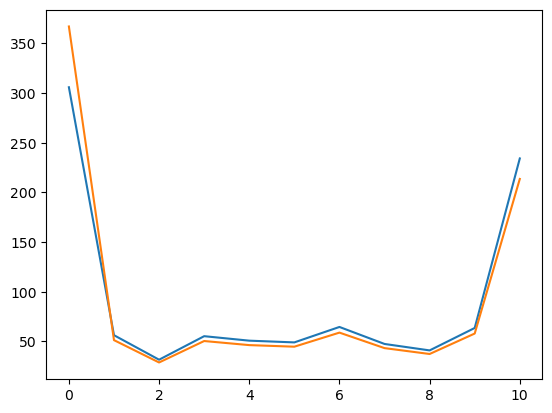

In [23]:
actions = [opt_result['trades']]
print('Original action:', actions)
increased_action = increase_front_load(opt_result['trades'], increase_fraction=0.2)
print('Increased action:', increased_action)
plt.plot(actions[0])
plt.plot(increased_action.flatten())


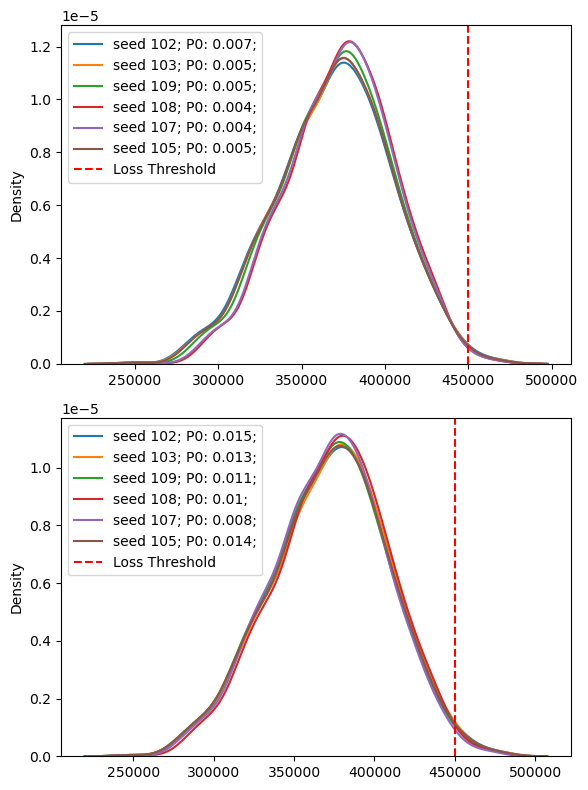

In [24]:
fig, axes = plt.subplots(2, 1, figsize=(6, 8))
pertubation = 0.51
for seed in seeds:
    with open(os.path.join(opt_results_dir, f'nScenarios{n_scenarios}_{seed}.pkl'), 'rb') as f:
        opt_result = pd.read_pickle(f)
    action = opt_result['trades']
    for i in range(len(axes)):
        ax = axes[i]
        action = perturb_actions(action, perturb_scale=pertubation * i)
        IS_arr = IS_tim(action, posterior_samples, n_steps, total_qty/scale, tau, sigma, spread) * scale
        violation_prob =  np.mean(IS_arr > opt_config['loss_thresh'])
        violation_prob_opt = opt_config['chance_thresh'] * (1 - opt_result['chance_slack'])
        sns.kdeplot(IS_arr, ax=ax, label=f'seed {seed}; P0: {violation_prob:.3g};')
for i, ax in enumerate(axes):
    ax.axvline(opt_config['loss_thresh'], color='red', linestyle='--', label='Loss Threshold')
    ax.legend()
plt.tight_layout()


/tmp/ipykernel_1035392/2322484318.py:28: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


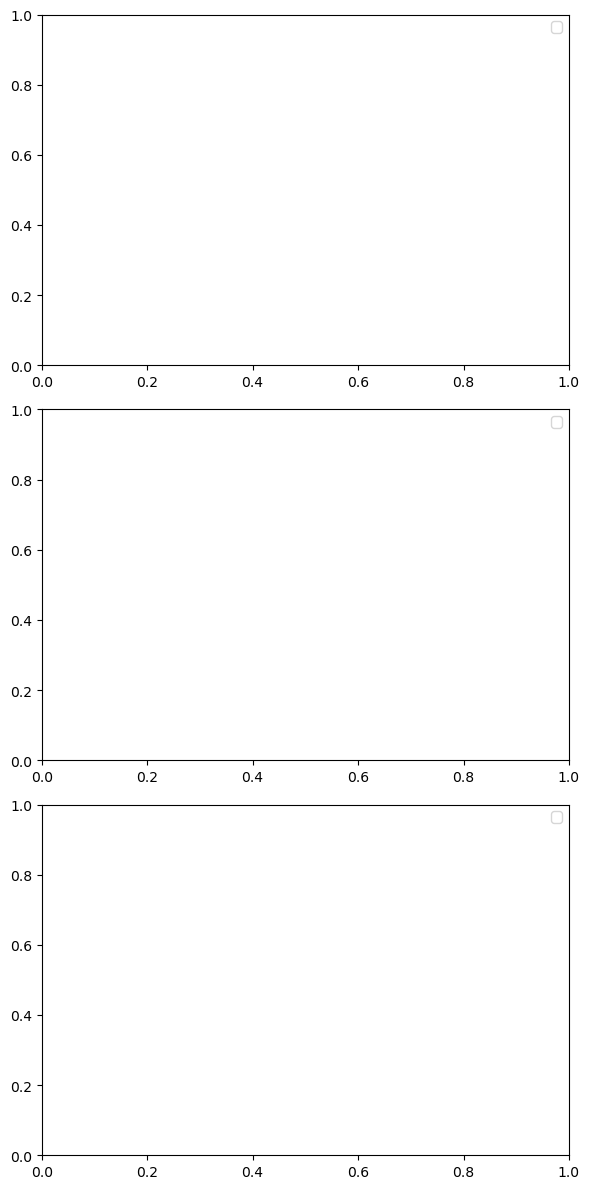

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(6, 12))
i = 0
kappa = 1e-5
gamma = 1e-5
rho = 2.231
n_scenarios = 1000
posterior_samples = {"gamma": [gamma]*n_scenarios, "kappa": [kappa]*n_scenarios, "rho": [rho]*n_scenarios}

for dir in os.listdir(opt_results_dir):
    if not os.path.isdir(os.path.join(opt_results_dir, dir)):
        continue
    ax = axes[i]
    i += 1
    sigma = float(dir.split('_sigma')[1].split('_')[0])
    
    for seed in seeds:
        with open(os.path.join(opt_results_dir, dir, f'nScenarios{n_scenarios}_{seed}.pkl'), 'rb') as f:
            opt_result = pd.read_pickle(f)
        action = opt_result['trades']
        IS_arr = IS_tim(action, posterior_samples, n_steps, total_qty, tau, sigma, spread) 
        p95 = np.percentile(IS_arr, 95)
        mean = np.mean(IS_arr)
        sns.kdeplot(IS_arr, ax=ax, label=f'mean: {mean:.3g}; P95: {p95:.3g};')
    ax.set_title(f'sigma = {sigma}')
for i, ax in enumerate(axes):
    # ax.axvline(opt_config['loss_thresh'], color='red', linestyle='--', label='Loss Threshold')
    ax.legend()
plt.tight_layout()

/tmp/ipykernel_1035392/3297905493.py:30: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


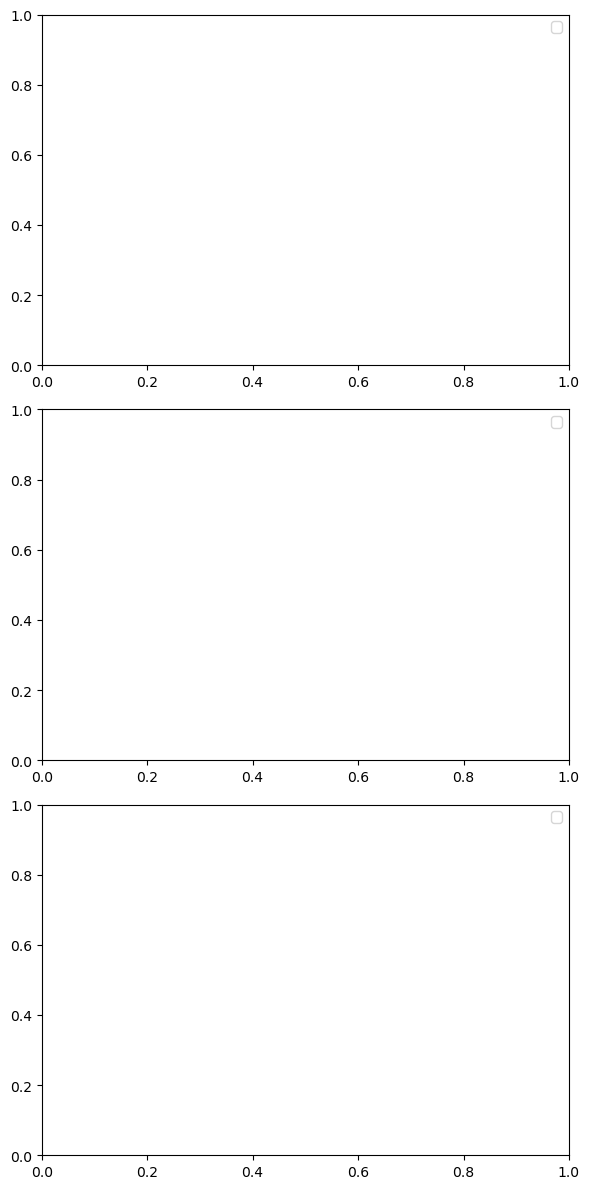

In [31]:
fig, axes = plt.subplots(3, 1, figsize=(6, 12))
i = 0
kappa = 1e-5
gamma = 1e-5
rho = 2.231
n_scenarios = 1000
posterior_samples = {"gamma": [gamma]*n_scenarios, "kappa": [kappa]*n_scenarios, "rho": [rho]*n_scenarios}
scales = [0., 1.]
for dir in os.listdir(opt_results_dir):
    if not os.path.isdir(os.path.join(opt_results_dir, dir)):
        continue
    ax = axes[i]
    i += 1
    sigma = float(dir.split('_sigma')[1].split('_')[0])
    seed = 100
    with open(os.path.join(opt_results_dir, dir, f'nScenarios{n_scenarios}_{seed}.pkl'), 'rb') as f:
            opt_result = pd.read_pickle(f)
    for scale in scales:
        action = opt_result['trades']
        action_new = increase_front_load(action, increase_fraction=scale)
        
        print(action_new[0])
        IS_arr = IS_tim(action_new, posterior_samples, n_steps, total_qty, tau, sigma, spread) 
        p95 = np.percentile(IS_arr, 95)
        mean = np.mean(IS_arr)
        sns.kdeplot(IS_arr, ax=ax, label=f'mean: {mean:.3g}; P95: {p95:.3g};')
    ax.set_title(f'sigma = {sigma}')
for i, ax in enumerate(axes):
    # ax.axvline(opt_config['loss_thresh'], color='red', linestyle='--', label='Loss Threshold')
    ax.legend()
plt.tight_layout()